In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'  # Решение проблемы с OpenMP

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# Импорты PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pycocotools.coco import COCO

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.7.1+cu128
CUDA available: True


In [2]:
# Параметры
IMG_SIZE = (256, 256)  # Размер изображений
BATCH_SIZE = 8         # Уменьшенный размер батча для стабильности

# Пути к данным (замените на свои реальные пути)
BASE_DIR = Path("archive/coco2017")
TRAIN_IMAGE_DIR = BASE_DIR / "filtered_train2017"
VAL_IMAGE_DIR = BASE_DIR / "filtered_val2017"
TRAIN_ANNOTATION = BASE_DIR / "annotations/filtered_train_annotations.json"
VAL_ANNOTATION = BASE_DIR / "annotations/filtered_val_annotations.json"

# Проверка путей
print("Проверка путей:")
print(f"Тренировочные изображения: {TRAIN_IMAGE_DIR.exists()}")
print(f"Валидационные изображения: {VAL_IMAGE_DIR.exists()}")
print(f"Тренировочные аннотации: {TRAIN_ANNOTATION.exists()}")
print(f"Валидационные аннотации: {VAL_ANNOTATION.exists()}")

Проверка путей:
Тренировочные изображения: True
Валидационные изображения: True
Тренировочные аннотации: True
Валидационные аннотации: True


In [3]:
# Загрузка аннотаций с обработкой ошибок
try:
    train_coco = COCO(TRAIN_ANNOTATION)
    val_coco = COCO(VAL_ANNOTATION)
    
    print("\nИнформация о датасете:")
    print(f"Тренировочные изображения: {len(train_coco.imgs)}")
    print(f"Тренировочные аннотации: {len(train_coco.anns)}")
    print(f"Валидационные изображения: {len(val_coco.imgs)}")
    print(f"Валидационные аннотации: {len(val_coco.anns)}")
    print(f"Категории: {[cat['name'] for cat in train_coco.cats.values()]}")
    
except Exception as e:
    print(f"Ошибка загрузки аннотаций: {str(e)}")

loading annotations into memory...
Done (t=0.69s)
creating index...
index created!
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!

Информация о датасете:
Тренировочные изображения: 15558
Тренировочные аннотации: 52905
Валидационные изображения: 673
Валидационные аннотации: 2267
Категории: ['bottle', 'wine glass', 'cup']


In [4]:
# Простые трансформации без аугментаций
image_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                         std=[0.229, 0.224, 0.225])
])

print("Трансформации созданы успешно")

Трансформации созданы успешно


In [5]:
class COCOSegmentationDataset(Dataset):
    def __init__(self, coco, img_dir, transform=None):
        self.coco = coco
        self.img_dir = img_dir
        self.transform = transform
        self.ids = list(coco.imgs.keys())
        
    def __len__(self):
        return len(self.ids)
    
    def __getitem__(self, idx):
        try:
            img_id = self.ids[idx]
            img_info = self.coco.loadImgs(img_id)[0]
            
            # Загрузка изображения
            img_path = self.img_dir / img_info['file_name']
            if not img_path.exists():
                raise FileNotFoundError(f"Файл {img_path} не найден")
                
            img = Image.open(img_path).convert('RGB')
            
            # Создание маски
            ann_ids = self.coco.getAnnIds(imgIds=img_id)
            anns = self.coco.loadAnns(ann_ids)
            mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
            
            for ann in anns:
                mask = np.maximum(mask, self.coco.annToMask(ann) * 255)
            
            mask = Image.fromarray(mask)
            
            # Применение трансформаций
            if self.transform:
                img = self.transform(img)
            
            # Обработка маски
            mask = transforms.Resize(IMG_SIZE, Image.NEAREST)(mask)
            mask = transforms.ToTensor()(mask)
            mask = (mask > 0).float()
            
            return img, mask
            
        except Exception as e:
            print(f"Ошибка в образце {idx}: {str(e)}")
            # Возвращаем пустые тензоры в случае ошибки
            dummy_img = torch.zeros(3, *IMG_SIZE)
            dummy_mask = torch.zeros(1, *IMG_SIZE)
            return dummy_img, dummy_mask

print("Класс датасета создан")

Класс датасета создан


In [6]:
# Создание датасетов
train_dataset = COCOSegmentationDataset(
    coco=train_coco,
    img_dir=TRAIN_IMAGE_DIR,
    transform=image_transform
)

val_dataset = COCOSegmentationDataset(
    coco=val_coco,
    img_dir=VAL_IMAGE_DIR,
    transform=image_transform
)

# Упрощенные DataLoader'ы
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0  # Отключаем multiprocessing для стабильности
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print(f"Тренировочных образцов: {len(train_dataset)}")
print(f"Валидационных образцов: {len(val_dataset)}")

Тренировочных образцов: 15558
Валидационных образцов: 673


Тренировочный набор:


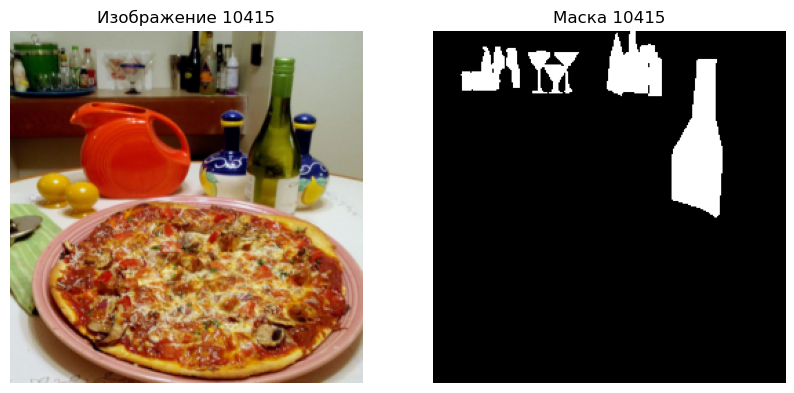


Валидационный набор:


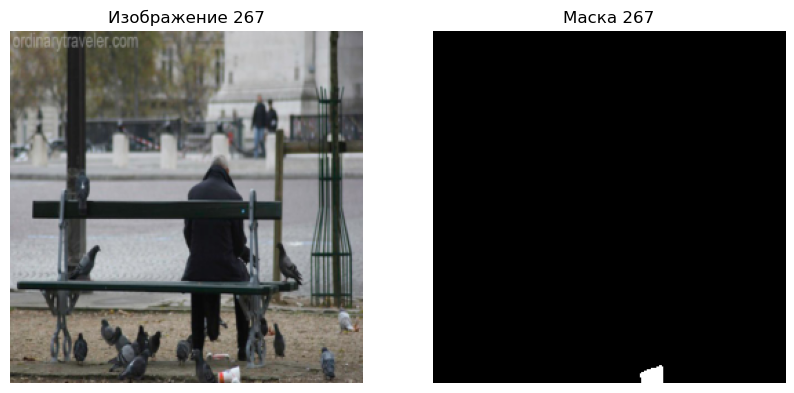

In [9]:
def visualize_one_sample(dataset, idx=None):
    """Визуализация одного образца с обработкой ошибок"""
    if idx is None:
        idx = random.randint(0, len(dataset)-1)
    
    try:
        img, mask = dataset[idx]
        
        # Денормализация изображения
        img_denorm = img.permute(1, 2, 0).numpy()
        img_denorm = img_denorm * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_denorm = np.clip(img_denorm, 0, 1)
        
        # Подготовка маски
        mask_np = mask.squeeze().numpy()
        
        # Визуализация
        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        ax[0].imshow(img_denorm)
        ax[0].set_title(f"Изображение {idx}")
        ax[0].axis('off')
        
        ax[1].imshow(mask_np, cmap='gray')
        ax[1].set_title(f"Маска {idx}")
        ax[1].axis('off')
        
        plt.show()
        
    except Exception as e:
        print(f"Ошибка визуализации: {str(e)}")

# Визуализируем по одному образцу из каждого набора
print("Тренировочный набор:")
visualize_one_sample(train_dataset)

print("\nВалидационный набор:")
visualize_one_sample(val_dataset)